# **Практическая работа №7. Random forest**

## **Задание 1. Обучите классификатор Random Forest для решения задачи бинарной классификации: для каждого человека научиться предсказывать, выживет ли он при крушении Титаника.**



Ссылка на датасет: https://www.kaggle.com/c/titanic/data

### 1. Устанавливаем зависимости

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

### 2. Импортируем датасет

In [2]:
train = pd.read_csv("train.csv")
test = pd.read_csv("test.csv")
submission = pd.read_csv("gender_submission.csv")

train.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


### 3. Производим разведовательный анализ данных


Получим представление о данных в датасете:

In [3]:
print(train.shape)
print(train.info())
print(train.isnull().sum())

train.describe(include="all")

(891, 12)
<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 118.9 KB
None
PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
count,891.000000,891.000000,891.000000,891,891,714.000000,891.000000,891.000000,891,891.000000,204,889
unique,NaN,NaN,NaN,891,2,NaN,NaN,NaN,681,NaN,147,3
top,NaN,NaN,NaN,"Braund, Mr. Owen Harris",male,NaN,NaN,NaN,347082,NaN,G6,S
freq,NaN,NaN,NaN,1,577,NaN,NaN,NaN,7,NaN,4,644
mean,446.000000,0.383838,2.308642,NaN,NaN,29.699118,0.523008,0.381594,NaN,32.204208,NaN,NaN
std,257.353842,0.486592,0.836071,NaN,NaN,14.526497,1.102743,0.806057,NaN,49.693429,NaN,NaN
min,1.000000,0.000000,1.000000,NaN,NaN,0.420000,0.000000,0.000000,NaN,0.000000,NaN,NaN
25%,223.500000,0.000000,2.000000,NaN,NaN,20.125000,0.000000,0.000000,NaN,7.910400,NaN,NaN
50%,446.000000,0.000000,3.000000,NaN,NaN,28.000000,0.000000,0.000000,NaN,14.454200,NaN,NaN
75%,668.500000,1.000000,3.000000,NaN,NaN,38.000000,1.000000,0.000000,NaN,31.000000,NaN,NaN


### 4. Сформируем обучающую и тестовую выборки:


In [4]:
from sklearn.model_selection import train_test_split

df = train.copy()

X = df.drop("Survived", axis=1)
y = df["Survived"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y
)

print(X_train.shape, X_test.shape)

(712, 11) (179, 11)


### 5. Feature Engineering

Поработаем с признаками, выделим важные, изменим форму их представления (при надобности)

In [5]:
features = ["Pclass", "Sex", "Age", "SibSp", "Parch", "Fare", "Embarked"]

a = train[features].copy()
b = test[features].copy()

a["Age"] = a["Age"].fillna(a["Age"].median())
b["Age"] = b["Age"].fillna(a["Age"].median())

a["Fare"] = a["Fare"].fillna(a["Fare"].median())
b["Fare"] = b["Fare"].fillna(a["Fare"].median())

a["Embarked"] = a["Embarked"].fillna(a["Embarked"].mode()[0])
b["Embarked"] = b["Embarked"].fillna(a["Embarked"].mode()[0])

a = pd.get_dummies(a, columns=["Sex", "Embarked"], drop_first=True)
b = pd.get_dummies(b, columns=["Sex", "Embarked"], drop_first=True)

b = b.reindex(columns=a.columns, fill_value=0)

X = a
y = train["Survived"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y
)

X.head()

,Pclass,Age,SibSp,Parch,Fare,Sex_male,Embarked_Q,Embarked_S
0,3,22.0,1,0,7.2500,True,False,True
1,1,38.0,1,0,71.2833,False,False,False
2,3,26.0,0,0,7.9250,False,False,True
3,1,35.0,1,0,53.1000,False,False,True
4,3,35.0,0,0,8.0500,True,False,True


### 6. Построение базовой модели:

In [6]:
from sklearn.ensemble import RandomForestClassifier

model = RandomForestClassifier(
    n_estimators=200,
    max_depth=5
)

model.fit(X_train, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",200
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",5
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap: bool, default=TrueWhether bootstrap samples are used when building trees. If False, thewhole dataset is used to build each tree.",True
,"oob_score oob_score: bool or callable, default=FalseWhether to use out-of-bag samples to estimate the generalization score.By default, :func:`~sklearn.metrics.accuracy_score` is used.Provide a callable with signature `metric(y_

### 7. Оценка точности модели:

#### 7.1. Напишите функцию, принимающую на вход аргументы y_pred, y_test и выполняющую визуализацию матрицы ошибок и отчета классификации

In [7]:
from sklearn.metrics import confusion_matrix, classification_report

def check_model(y_test, y_pred):
    a = confusion_matrix(y_test, y_pred)

    sns.heatmap(a, annot=True, fmt="d", cmap="Blues")
    plt.xlabel("Предсказанный класс")
    plt.ylabel("Истинный класс")
    plt.show()

    print(classification_report(y_test, y_pred))

#### 7.2. Оцените точность модели:

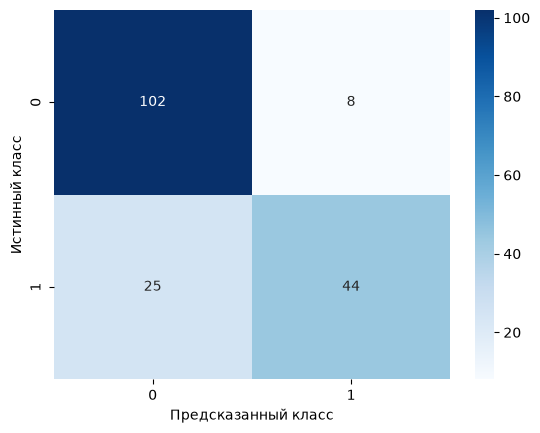

              precision    recall  f1-score   support

           0       0.80      0.93      0.86       110
           1       0.85      0.64      0.73        69

    accuracy                           0.82       179
   macro avg       0.82      0.78      0.79       179
weighted avg       0.82      0.82      0.81       179



In [8]:
y_pred = model.predict(X_test)

check_model(y_test, y_pred)

### 8. Тюнинг гиперпараметров модели:

#### RandomSearchCV

In [9]:
from sklearn.model_selection import RandomizedSearchCV

params = {
    "n_estimators": [100, 200, 300, 500],
    "max_depth": [3, 5, 7, 10, None],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 4],
    "max_features": ["sqrt", "log2"]
}

a = RandomizedSearchCV(
    RandomForestClassifier(),
    params,
    n_iter=10,
    cv=3,
    scoring="accuracy",
    n_jobs=1
)

a.fit(X_train, y_train)

print(a.best_params_)
print(a.best_score_)

{'n_estimators': 500, 'min_samples_split': 10, 'min_samples_leaf': 2, 'max_features': 'sqrt', 'max_depth': 7}
0.8202259806876336


#### GridSearchCV

In [10]:
from sklearn.model_selection import GridSearchCV

b = a.best_params_

params = {
    "n_estimators": [max(50, b["n_estimators"] - 100), b["n_estimators"], b["n_estimators"] + 100],
    "max_depth": [b["max_depth"]] if b["max_depth"] is None else [max(2, b["max_depth"] - 2), b["max_depth"], b["max_depth"] + 2],
    "min_samples_split": [b["min_samples_split"]],
    "min_samples_leaf": [b["min_samples_leaf"]],
    "max_features": [b["max_features"]]
}

c = GridSearchCV(
    RandomForestClassifier(),
    params,
    cv=3,
    scoring="accuracy",
    n_jobs=1
)

c.fit(X_train, y_train)

best_model = c.best_estimator_

print(c.best_params_)
print(c.best_score_)

{'max_depth': 7, 'max_features': 'sqrt', 'min_samples_leaf': 2, 'min_samples_split': 10, 'n_estimators': 600}
0.823038920209434


### 9. Комплексная оценка точности лучшей модели:

Accuracy: 0.8156424581005587
Precision: 0.86
Recall: 0.6231884057971014
F1: 0.7226890756302521


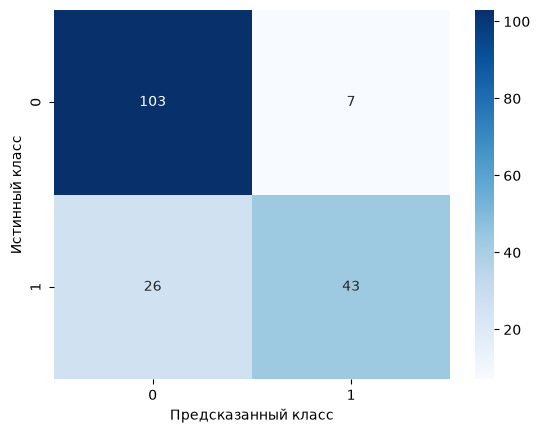

              precision    recall  f1-score   support

           0       0.80      0.94      0.86       110
           1       0.86      0.62      0.72        69

    accuracy                           0.82       179
   macro avg       0.83      0.78      0.79       179
weighted avg       0.82      0.82      0.81       179



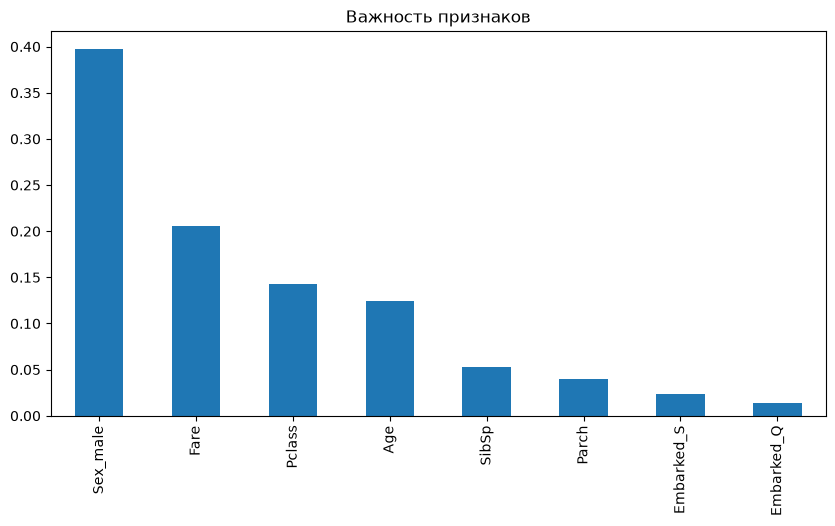

In [11]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

y_pred = best_model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred))
print("Recall:", recall_score(y_test, y_pred))
print("F1:", f1_score(y_test, y_pred))

check_model(y_test, y_pred)

a = pd.Series(best_model.feature_importances_, index=X.columns)
a = a.sort_values(ascending=False)

a.plot(kind="bar", figsize=(10, 5))
plt.title("Важность признаков")
plt.show()

## **Задание 2. Решите задачу из предыдущего пункта используя другие, ранее пройденные классификаторы. Сравните их точность предсказания с Random Forest**

In [12]:
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score

models = {
    "Random Forest": best_model,
    "Logistic Regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)),
    "KNN": make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5)),
    "Decision Tree": DecisionTreeClassifier(max_depth=5)
}

result = []

for name, m in models.items():
    m.fit(X_train, y_train)
    pred = m.predict(X_test)
    result.append([name, accuracy_score(y_test, pred)])

pd.DataFrame(result, columns=["Модель", "Accuracy"]).sort_values(
    "Accuracy", ascending=False
)

,Модель,Accuracy
3,Decision Tree,0.815642
0,Random Forest,0.810056
1,Logistic Regression,0.793296
2,KNN,0.782123


## **Задание 2.1. Реализуйте функцию, для взаимодействия с обученной Вами моделью**



* Функция должна принимать на вход обученную модель классификатора;

* После вызова функции, у пользователя через консоль запрашиваются значения признаков. При запросе значений нужно вывести пояснения о типе и диапазоне возможных значений. Также реализуйте обработку исключений;

* После ввода значений для всех признаков в консоль, выводится результат работы классификатора.

In [13]:
def passenger_prediction(model):
    print("Введите данные пассажира")

    pclass = int(input("Класс билета (1, 2 или 3): "))
    sex = input("Пол (male/female): ").strip().lower()
    age = float(input("Возраст: "))
    sibsp = int(input("Количество братьев/сестёр/супругов на борту: "))
    parch = int(input("Количество родителей/детей на борту: "))
    fare = float(input("Стоимость билета: "))
    embarked = input("Порт посадки (C, Q или S): ").strip().upper()

    a = pd.DataFrame([{
        "Pclass": pclass,
        "Age": age,
        "SibSp": sibsp,
        "Parch": parch,
        "Fare": fare,
        "Sex_male": sex == "male",
        "Embarked_Q": embarked == "Q",
        "Embarked_S": embarked == "S"
    }])

    a = a.reindex(columns=X.columns, fill_value=0)

    pred = model.predict(a)[0]

    if pred == 1:
        print("Предсказание: пассажир выжил")
    else:
        print("Предсказание: пассажир не выжил")

# Пример запуска:
# passenger_prediction(best_model)

## **Задание 3. Решите задачу регрессии, используя [RandomForestRegressor](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestRegressor.html).**

**ОБЯЗАТЕЛЬНО ОСУЩЕСТВИТЕ ПОДБОР ОПТИМАЛЬНЫХ ПАРАМЕТРОВ, ИСПОЛЬЗУЯ RandomSearchCV и GridSearchCV**



* Для выполнения данного задания можете использовать **любой датасет**



Ссылка на один из сайтов-источников датасетов: https://www.kaggle.com/datasets?tags=14203-Regression

In [14]:
from sklearn.datasets import load_diabetes
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split, RandomizedSearchCV, GridSearchCV
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

data = load_diabetes(as_frame=True)

X = data.data
y = data.target

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2
)

params = {
    "n_estimators": [100, 200, 300],
    "max_depth": [3, 5, 7, 10, None],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 4]
}

a = RandomizedSearchCV(
    RandomForestRegressor(),
    params,
    n_iter=10,
    cv=3,
    scoring="r2",
    n_jobs=1
)

a.fit(X_train, y_train)

print("RandomSearch:", a.best_params_)

b = a.best_params_

params2 = {
    "n_estimators": [max(50, b["n_estimators"] - 100), b["n_estimators"], b["n_estimators"] + 100],
    "max_depth": [b["max_depth"]] if b["max_depth"] is None else [max(2, b["max_depth"] - 2), b["max_depth"], b["max_depth"] + 2],
    "min_samples_split": [b["min_samples_split"]],
    "min_samples_leaf": [b["min_samples_leaf"]]
}

c = GridSearchCV(
    RandomForestRegressor(),
    params2,
    cv=3,
    scoring="r2",
    n_jobs=1
)

c.fit(X_train, y_train)

model_reg = c.best_estimator_

pred = model_reg.predict(X_test)

print("GridSearch:", c.best_params_)
print("MAE:", mean_absolute_error(y_test, pred))
print("MSE:", mean_squared_error(y_test, pred))
print("RMSE:", np.sqrt(mean_squared_error(y_test, pred)))
print("R2:", r2_score(y_test, pred))

RandomSearch: {'n_estimators': 300, 'min_samples_split': 10, 'min_samples_leaf': 2, 'max_depth': 10}
GridSearch: {'max_depth': 10, 'min_samples_leaf': 2, 'min_samples_split': 10, 'n_estimators': 200}
MAE: 49.93320208834092
MSE: 3713.550909552272
RMSE: 60.938911292804306
R2: 0.28184286789036817


## **Задание №4. Интерпретация моделей, основанных на решающих деревьях, в задачах контроля качества**

- Для компании-произвозителя собачьего корма, необходимо попытаться предсказать, почему некоторые партии их корма портятся гораздо быстрее, чем предполагалось.

- К сожалению, эта компания по производству собачьего корма не обновила свое оборудование до последних моделей, что означает, что количество пяти консервантов, которые они используют, может значительно варьироваться. Но какой из консервантов оказывает наибольшее влияние?

- Сначала компания по производству собачьего корма готовит партию консерванта, которая содержит 4 разных консерванта (A, B, C, D), а затем добавляет "наполнитель". Ученые полагают, что один из консервантов A, B, C или D вызывает проблему и необходимо выяснить, какой именно.



Используйте алгоритм случайного леса (Random Forest) для определения важности признаков. На основе полученных результатов установите, какой именно консервант (A, B, C или D) в наибольшей степени влияет на преждевременную порчу партий собачьего корма.

* Pres_A : Процент консерванта A в смеси
* Pres_B : Процент консерванта B в смеси
* Pres_C : Процент консерванта C в смеси
* Pres_D : Процент консерванта D в смеси
* Spoiled: Метка, указывающая, испортилась ли партия собачьего корма.



#### **Загрузка исходные данных (запустите эту ячейку!)**

___

#### **Тщательно подумайте о том, что на самом деле требуется решить в этой задаче!**
____

In [20]:
import pandas as pd

data = pd.read_csv('dog_food.csv')

In [21]:
data.head()

,A,B,C,D,Spoiled
0,4,2,12.0,3,1.0
1,5,6,12.0,7,1.0
2,6,2,13.0,6,1.0
3,4,2,12.0,1,1.0
4,4,2,12.0,3,1.0


C    0.909025
D    0.034382
A    0.028744
B    0.027848
dtype: float64


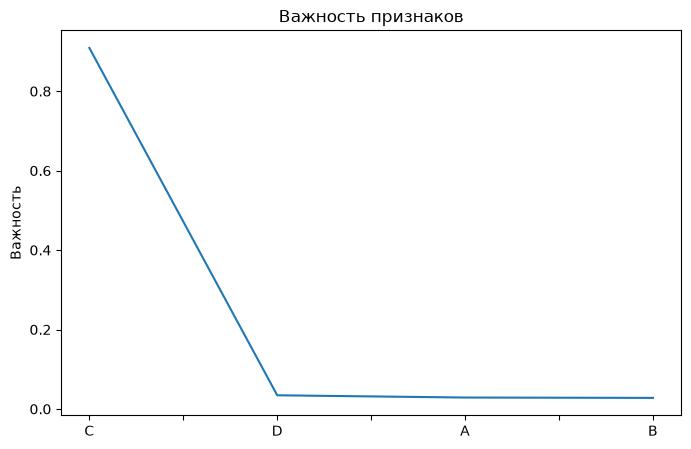

Сильнее всего влияет: C


In [28]:
from sklearn.ensemble import RandomForestClassifier

X = data.drop("Spoiled", axis=1)
y = data["Spoiled"]

model = RandomForestClassifier(n_estimators=300)
model.fit(X, y)

a = pd.Series(
    model.feature_importances_,
    index=X.columns
).sort_values(ascending=False)

print(a)

a.plot(figsize=(8, 5))
plt.ylabel("Важность")
plt.title("Важность признаков")
plt.show()

print("Сильнее всего влияет:", a.index[0])